# 1D Stiff Relaxation: IMEX (Implicit-Explicit) Schemes & Asymptotic Preserving Limit

In the previous notebook, we saw that treating the relaxation term $-\kappa F$ explicitly imposes a severe stability restriction ($\kappa \Delta t \lesssim 2 - \text{CFL}$), forcing the timestep to shrink as $\Delta t \propto 1/\kappa$ in the optically thick (or high-conductivity) regime.

To overcome this without solving a global coupled linear system across the grid, we use an **IMEX (Implicit-Explicit)** time-stepping approach:
- **Spatial fluxes (non-stiff hyperbolic transport)** are treated **explicitly**, bounded only by the acoustic/light-speed CFL condition $\Delta t = \text{CFL}\,\Delta x / c$.
- **Local relaxation sources (stiff collision/resistive terms)** are treated **implicitly**.

Because $-\kappa F$ is strictly local to each grid cell $i$, the implicit step requires only a trivial scalar division per cell!

In [1]:
### IMPORT LIBRARIES ###

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

# Characteristic speed of the hyperbolic part
c = 1.0 / np.sqrt(3.0)

## 1. First-Order IMEX Euler (Operator Splitting)

Consider splitting the update from $t^n$ to $t^{n+1}$ into two stages:
1. **Explicit hyperbolic transport step:**
   $$E^{n+1} = E^n - \frac{\Delta t}{\Delta x}\left(\hat{f}^E_{i+1/2} - \hat{f}^E_{i-1/2}\right)$$
   $$F^* = F^n - \frac{\Delta t}{\Delta x}\left(\hat{f}^F_{i+1/2} - \hat{f}^F_{i-1/2}\right)$$

2. **Implicit local relaxation step (Backward Euler on the source):**
   $$F^{n+1} = F^* - \kappa \Delta t F^{n+1} \implies F^{n+1} = \frac{F^*}{1 + \kappa \Delta t}$$

Notice the crucial **Asymptotic Preserving (AP)** property: as $\kappa \Delta t \to \infty$, $F^{n+1} \approx \frac{F^*}{\kappa \Delta t} \approx -\frac{1}{3\kappa}\partial_x E^n$, recovering Fick's diffusion law automatically without reducing $\Delta t$!

In [2]:
### DEFINE FUNCTION TO SOLVE THE 1D TELEGRAPH/P1 SYSTEM USING IMEX EULER ###

def run_imex_euler(kappa, N=200, cfl=0.9, tend=0.5):
    """
    Solve the 1D telegraph/P1 system using 1st-order IMEX Euler:
    - Explicit Rusanov fluxes for spatial derivatives
    - Implicit Backward Euler for the stiff relaxation source -kappa * F
    """
    dx = 1.0 / N
    x = (np.arange(N) + 0.5) * dx
    
    # Initial condition: Gaussian energy pulse at rest
    sigma0 = 0.05
    E = np.exp(-(x - 0.5)**2 / (2.0 * sigma0**2))
    F = np.zeros(N)
    
    dt = cfl * dx / c
    t = 0.0
    ts = [0.0]
    Fmax = [0.0]
    
    while t < tend:
        # Adjust final step to hit tend cleanly
        dt_step = min(dt, tend - t)
        
        Ep, Fp = np.roll(E, -1), np.roll(F, -1)
        
        # Explicit Rusanov fluxes
        fE = 0.5 * (F + Fp) - 0.5 * c * (Ep - E)
        fF = 0.5 * (E / 3.0 + Ep / 3.0) - 0.5 * c * (Fp - F)
        
        # Explicit hyperbolic update
        E_new = E - (dt_step / dx) * (fE - np.roll(fE, 1))
        F_star = F - (dt_step / dx) * (fF - np.roll(fF, 1))
        
        # Implicit relaxation update (unconditionally stable for any kappa > 0)
        F_new = F_star / (1.0 + kappa * dt_step)
        
        E, F = E_new, F_new
        t += dt_step
        ts.append(t)
        Fmax.append(np.max(np.abs(F)))
        
    return x, E, F, np.array(ts), np.array(Fmax), dt

## 2. Testing Unconditional Stability Across Stiffness Regimes

In the explicit scheme, the simulation blew up at $\kappa \approx 220$. Let us now push $\kappa$ up to $10^5$ ($\kappa \Delta t \sim 10^3$) using the exact same CFL-governed timestep $\Delta t$:

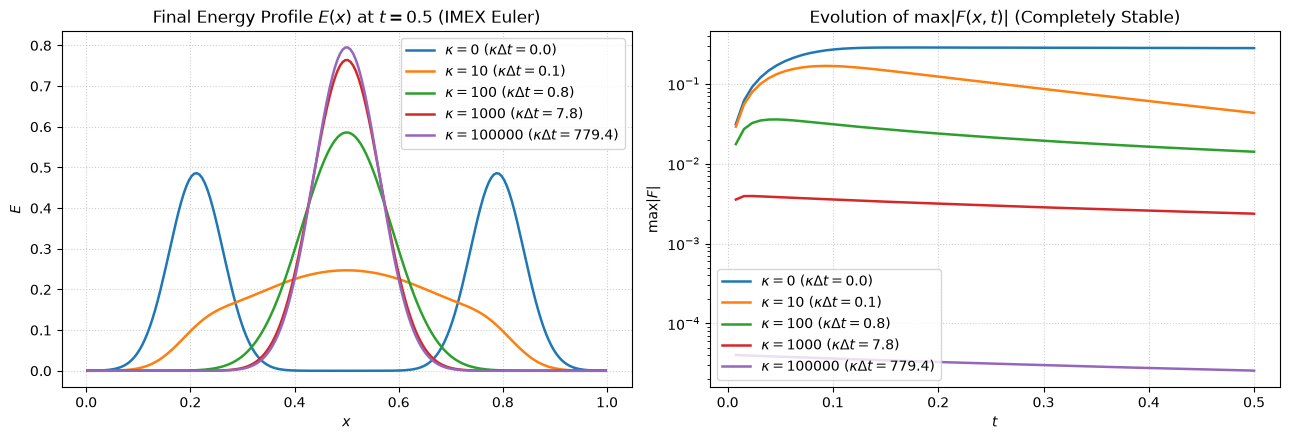

In [3]:
### RUN SIMULATION FOR DIFFERENT KAPPA VALUES AND PLOT RESULTS ###

kappas = [0, 10, 100, 1000, 1e5]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for k in kappas:
    x, E, F, ts, Fmax, dt = run_imex_euler(k, tend=0.5)
    label = rf"$\kappa={k:g}$ ($\kappa\Delta t={k*dt:.1f}$)"
    axes[0].plot(x, E, lw=1.8, label=label)
    axes[1].semilogy(ts[1:], Fmax[1:], lw=1.8, label=label)

axes[0].set_title(r"Final Energy Profile $E(x)$ at $t=0.5$ (IMEX Euler)")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$E$")
axes[0].grid(True, ls=":", alpha=0.6)
axes[0].legend()

axes[1].set_title(r"Evolution of $\max |F(x,t)|$ (Completely Stable)")
axes[1].set_xlabel("$t$")
axes[1].set_ylabel(r"$\max |F|$")
axes[1].grid(True, ls=":", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Subtle Trap: Numerical Diffusion in the Asymptotic Limit!

Wait a second! Look closely at the curve for $\kappa = 10^5$ above. In the physical diffusion limit ($\kappa \to \infty$), the diffusion coefficient is $D = \frac{1}{3\kappa}$. For $\kappa = 10^5$ and $t = 0.5$, $D t \approx 1.67 \times 10^{-6}$, meaning the initial Gaussian pulse should **barely move at all**!

Why did the numerical solution broaden noticeably for $\kappa = 10^5$?

Look at the Rusanov dissipation term in the flux of $E$:
$$\hat{f}^E_{i+1/2} = \frac{1}{2}(F_i + F_{i+1}) - \frac{c}{2}(E_{i+1} - E_i)$$

That $-\frac{c}{2}(E_{i+1} - E_i)$ term introduces an artificial numerical diffusion $D_{\rm num} = \frac{1}{2} c \Delta x$. When $\kappa$ is huge, $D_{\rm phys} = \frac{1}{3\kappa} \ll D_{\rm num}$, so the Rusanov wave speed $c$ completely swamps the true physical diffusion!

Let us verify this by comparing $\kappa = 500$ (where $D_{\rm phys}$ is moderate) against the exact analytical solution of the heat equation $\partial_t E = D \partial_x^2 E$:

$$E_{\rm exact}(x, t) = \frac{\sigma_0}{\sqrt{\sigma_0^2 + 2 D t}} \exp\left(-\frac{(x - 0.5)^2}{2(\sigma_0^2 + 2 D t)}\right)$$

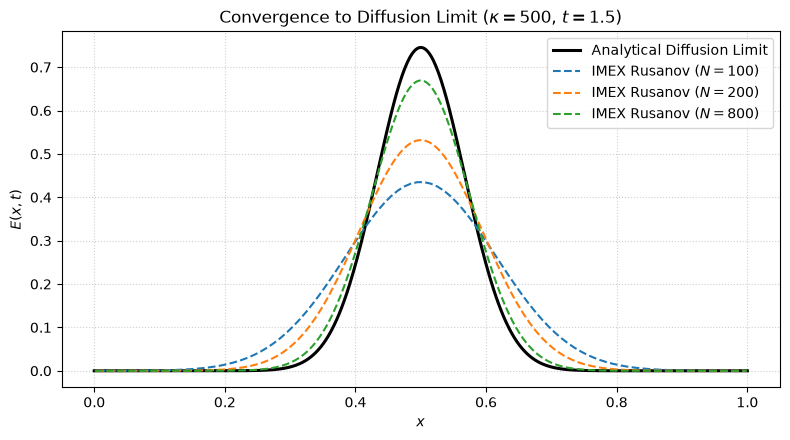

In [4]:
### DEFINE FUNCTION FOR ANALYTICAL DIFFUSION LIMIT ###

def analytical_diffusion(x, t, kappa, sigma0=0.05):
    D = 1.0 / (3.0 * kappa)
    sigma_t2 = sigma0**2 + 2.0 * D * t
    return (sigma0 / np.sqrt(sigma_t2)) * np.exp(-(x - 0.5)**2 / (2.0 * sigma_t2))

kappa_test = 500.0
tend_diff = 1.5

plt.figure(figsize=(8, 4.5))
x_ex = np.linspace(0, 1, 500)
plt.plot(x_ex, analytical_diffusion(x_ex, tend_diff, kappa_test), "k-", lw=2.2, label="Analytical Diffusion Limit")

for N_grid in [100, 200, 800]:
    x, E, _, _, _, _ = run_imex_euler(kappa_test, N=N_grid, tend=tend_diff)
    plt.plot(x, E, "--", lw=1.5, label=rf"IMEX Rusanov ($N={N_grid}$)")

plt.title(rf"Convergence to Diffusion Limit ($\kappa={kappa_test:g}$, $t={tend_diff}$)")
plt.xlabel("$x$")
plt.ylabel("$E(x,t)$")
plt.grid(True, ls=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Key Takeaways for Relativistic MHD & M1 Neutrino Transport

1. **Why IMEX is mandatory:** In binary neutron star mergers, neutrino opacity $\kappa$ spans 10+ orders of magnitude—from $\kappa \approx 0$ in the exterior (free-streaming at $c$) to $\kappa \Delta t \gg 10^6$ inside the hypermassive neutron star core. IMEX handles both regimes seamlessly with a single explicit CFL timestep.
2. **Wave-speed rescaling in optically thick cells:** As seen in Section 3, standard Rusanov fluxes add excessive numerical dissipation $\propto c\Delta x$ when $\kappa \Delta x \gg 1$. Production M1 codes (such as those developed at IAC3 / UIB) rescale the characteristic wave speeds inside the Riemann solver by a factor $\sim \min(1, \frac{1}{\kappa \Delta x})$ so the numerical scheme accurately recovers the asymptotic parabolic diffusion limit even on coarse grids!